# Decoding cursor intention, and watching it decay

This notebook trains a small decoder to predict the cursor-to-target displacement from threshold-crossing rates, which is the regression the paper uses for its offline analyses.

The interesting part is not the within-day fit, it is what happens afterwards. Because the release spans five years of the same two arrays, we can train on one day and test on days that are two, fourteen, or nine hundred days later. That decay is the entire motivation for the recalibration methods the paper develops, and it is what this dataset is uniquely good for.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import neuralset as ns

from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.wilson_2025.study import Wilson2025CursorRecalibration
from neuralshed.extractors import BehavioralSeriesExtractor, NeuralFeatureExtractor

torch.manual_seed(0)

# 1 s windows on the source 50 Hz grid, stepped by 1 s.
FS = 50.0
WINDOW_S = 1.0
STRIDE_S = 1.0

## Choosing sessions

We use the radial-8 `cursor` task only, restricted to the authors' analysis blocks, and take the nine days that have at least four such blocks. They happen to span a useful range of gaps, from two days to two and a half years.

In [2]:
SESSIONS = [
    "t5.2016.09.26",
    "t5.2016.09.28",
    "t5.2016.10.03",
    "t5.2016.10.05",
    "t5.2016.10.10",
    "t5.2017.09.20",
    "t5.2018.08.22",
    "t5.2018.09.17",
    "t5.2019.03.27",
]
TRAIN_SESSION = SESSIONS[0]

study = Wilson2025CursorRecalibration(
    path=str(dataset_dir("wilson_2025") / "data"),
    query=f"session in {SESSIONS} and task == 'cursor' and analysis_block",
)
events = study.run()

blocks = events[["session", "run", "post_implant_day"]].drop_duplicates()
print(f"blocks: {len(blocks)} across {blocks.session.nunique()} sessions")
print(blocks.groupby("session").agg(blocks=("run", "size"), day=("post_implant_day", "first")).to_string())

blocks: 53 across 9 sessions
               blocks  day
session                   
t5.2016.09.26       6   40
t5.2016.09.28       8   42
t5.2016.10.03       5   47
t5.2016.10.05       5   49
t5.2016.10.10       7   54
t5.2017.09.20       7  399
t5.2018.08.22       4  735
t5.2018.09.17       4  761
t5.2019.03.27       7  952


## Windowing

Sliding 1 s windows over each whole block give the neural input and the two behavioral streams the target is built from. Triggering on `SpikeCounts` windows the entire block rather than only the trial spans.

In [3]:
segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(target_unit="Hz", frequency=FS, event_types="SpikeCounts"),
        "cursor": BehavioralSeriesExtractor(frequency=FS, event_types="CursorPositionSeries"),
        "target": BehavioralSeriesExtractor(frequency=FS, event_types="TargetPositionSeries"),
    },
    trigger_query="type == 'SpikeCounts'",
    start=0.0,
    duration=WINDOW_S,
    stride=STRIDE_S,
)
segments = segmenter.apply(events)
segments.prepare()

batch = segments.load_all()
neural = batch.data["neural"].float()
cursor = batch.data["cursor"].float()
target = batch.data["target"].float()

print(f"neural {tuple(neural.shape)}  cursor {tuple(cursor.shape)}  target {tuple(target.shape)}")

2026-08-14 17:40:28 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


  0%|          | 0/53 [00:00<?, ?it/s]

  4%|▍         | 2/53 [00:00<00:04, 11.51it/s]

  8%|▊         | 4/53 [00:00<00:03, 12.26it/s]

 11%|█▏        | 6/53 [00:00<00:03, 12.55it/s]

...

 89%|████████▊ | 47/53 [00:03<00:00, 12.64it/s]

 92%|█████████▏| 49/53 [00:03<00:00, 13.62it/s]

 96%|█████████▌| 51/53 [00:03<00:00, 12.06it/s]

100%|██████████| 53/53 [00:03<00:00, 14.15it/s]

neural (11093, 192, 50)  cursor (11093, 2, 50)  target (11093, 2, 50)


The regression target is the instantaneous displacement from cursor to target, in screen pixels. Windows containing a NaN (a block edge) are dropped.

In [4]:
displacement = target - cursor

finite = (
    torch.isfinite(neural).all(dim=(1, 2))
    & torch.isfinite(displacement).all(dim=(1, 2))
)
neural, displacement = neural[finite], displacement[finite]
triggers = batch.triggers[finite.numpy()].reset_index(drop=True)

print(f"windows kept: {len(neural)} of {len(finite)}")
print(f"displacement range: {displacement.min():.0f} to {displacement.max():.0f} px")

windows kept: 11093 of 11093
displacement range: -949 to 1249 px


## Splitting

Training uses the first day only. Two of its blocks are held out as a within-day validation set, and every other day becomes its own test set. This keeps the comparison clean: the same decoder, the same task, only the calendar gap changes.

In [5]:
session_of = triggers["session"].to_numpy()
run_of = triggers["run"].to_numpy()
day_of = triggers["post_implant_day"].to_numpy().astype(int)

train_runs = sorted(set(run_of[session_of == TRAIN_SESSION]))
val_runs = set(train_runs[-2:])

is_train_session = session_of == TRAIN_SESSION
is_val = is_train_session & np.isin(run_of, list(val_runs))
is_train = is_train_session & ~is_val

print(f"train blocks: {sorted(set(train_runs) - val_runs)}")
print(f"val blocks:   {sorted(val_runs)}")
print(f"train windows {is_train.sum()}  val windows {is_val.sum()}")

train blocks: ['block07', 'block12', 'block19', 'block21']
val blocks:   ['block24', 'block29']
train windows 673  val windows 341


Normalization statistics come from the training blocks only, and are then applied unchanged to every later day. That is deliberate: refitting them per day would be a mild form of the mean recalibration the paper benchmarks, and would hide part of the drift we want to see.

In [6]:
train_idx = torch.tensor(np.flatnonzero(is_train))
val_idx = torch.tensor(np.flatnonzero(is_val))

x_mean = neural[train_idx].mean(dim=(0, 2), keepdim=True)
x_std = neural[train_idx].std(dim=(0, 2), keepdim=True) + 1e-6
y_scale = displacement[train_idx].std()


def prepare(idx):
    return (neural[idx] - x_mean) / x_std, displacement[idx] / y_scale


x_train, y_train = prepare(train_idx)
x_val, y_val = prepare(val_idx)
print(f"y scale: {y_scale:.1f} px")
print(f"x_train {tuple(x_train.shape)}  y_train {tuple(y_train.shape)}")

y scale: 181.0 px
x_train (673, 192, 50)  y_train (673, 2, 50)


## A small decoder

A two-layer temporal convolution over the 192 channels, predicting displacement at every timestep. It is deliberately small: the point here is the drift comparison, not squeezing out the best within-day fit.

In [7]:
class DisplacementDecoder(nn.Module):
    def __init__(self, n_in, n_out=2, hidden=96, kernel=9, dropout=0.3):
        super().__init__()
        pad = kernel // 2
        self.net = nn.Sequential(
            nn.Conv1d(n_in, hidden, kernel, padding=pad),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(hidden, hidden, kernel, padding=pad),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(hidden, n_out, 1),
        )

    def forward(self, x):
        return self.net(x)


model = DisplacementDecoder(neural.shape[1])
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

parameters: 249,218


In [8]:
loader = DataLoader(TensorDataset(x_train, y_train), batch_size=64, shuffle=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
loss_fn = nn.MSELoss()

history = []
for epoch in range(25):
    model.train()
    total = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(x_val), y_val).item()
    history.append((total / len(x_train), val_loss))
    if epoch % 5 == 0 or epoch == 24:
        print(f"epoch {epoch:2d}  train {history[-1][0]:.4f}  val {val_loss:.4f}")

epoch  0  train 0.6360  val 0.5443


epoch  5  train 0.2290  val 0.4868


epoch 10  train 0.1221  val 0.4848


epoch 15  train 0.0970  val 0.4951


epoch 20  train 0.0849  val 0.4806


epoch 24  train 0.0770  val 0.4566


## Metrics

Both metrics are computed in the original pixel units. `r` is the Pearson correlation between predicted and true displacement, averaged over the x and y dimensions, which is what the paper reports. `R2` is the coefficient of determination, which additionally punishes getting the scale or the offset wrong, so it is the harsher of the two.

In [9]:
def evaluate(idx):
    x, y = prepare(idx)
    with torch.no_grad():
        pred = model(x)
    # back to pixels, then flatten windows and time into one long series per dimension
    pred = (pred * y_scale).permute(1, 0, 2).reshape(2, -1).numpy()
    true = (y * y_scale).permute(1, 0, 2).reshape(2, -1).numpy()

    correlations, r2s = [], []
    for dim in range(2):
        correlations.append(np.corrcoef(pred[dim], true[dim])[0, 1])
        residual = ((true[dim] - pred[dim]) ** 2).sum()
        total = ((true[dim] - true[dim].mean()) ** 2).sum()
        r2s.append(1 - residual / total)
    return float(np.mean(correlations)), float(np.mean(r2s))


model.eval()
train_r, train_r2 = evaluate(train_idx)
val_r, val_r2 = evaluate(val_idx)
print(f"train blocks      r={train_r:.3f}  R2={train_r2:+.3f}")
print(f"held-out same day r={val_r:.3f}  R2={val_r2:+.3f}")

train blocks      r=0.987  R2=+0.971
held-out same day r=0.758  R2=+0.558


## The decay

Now the same frozen decoder is applied to every other day.

In [10]:
base_day = day_of[is_train_session][0]
results = [("held-out same day", 0, val_r, val_r2)]

for session in SESSIONS[1:]:
    idx = torch.tensor(np.flatnonzero(session_of == session))
    gap = int(day_of[session_of == session][0] - base_day)
    r, r2 = evaluate(idx)
    results.append((session, gap, r, r2))

print(f"{'session':22s} {'days apart':>10s} {'r':>7s} {'R2':>8s}")
for name, gap, r, r2 in results:
    print(f"{name:22s} {gap:10d} {r:7.3f} {r2:+8.3f}")

session                days apart       r       R2
held-out same day               0   0.758   +0.558
t5.2016.09.28                   2   0.742   +0.528
t5.2016.10.03                   7   0.477   +0.139
t5.2016.10.05                   9   0.579   +0.156
t5.2016.10.10                  14   0.179   -0.071
t5.2017.09.20                 359  -0.038   -0.084
t5.2018.08.22                 695  -0.045   -0.166
t5.2018.09.17                 721  -0.087   -0.079
t5.2019.03.27                 912  -0.142   -0.241


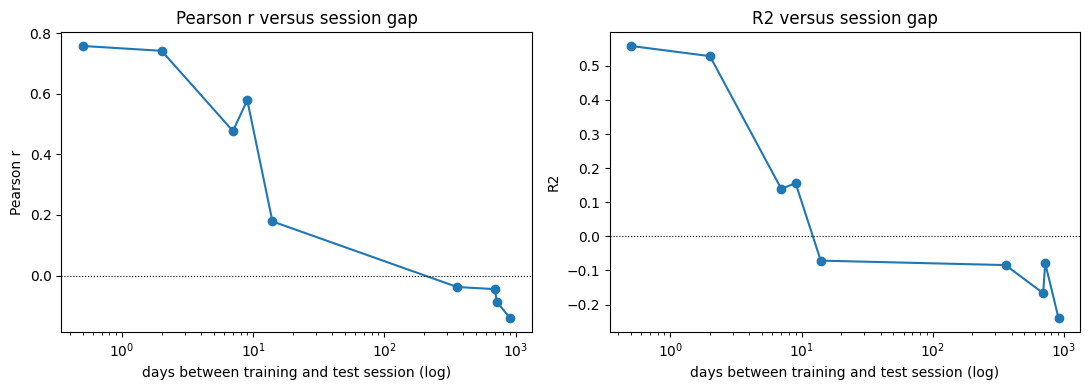

In [11]:
gaps = np.array([gap for _, gap, _, _ in results])
rs = np.array([r for _, _, r, _ in results])
r2s = np.array([r2 for _, _, _, r2 in results])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, label in zip(axes, [rs, r2s], ["Pearson r", "R2"]):
    ax.plot(np.maximum(gaps, 0.5), values, "o-", ms=6)
    ax.set_xscale("log")
    ax.axhline(0, color="k", lw=0.8, ls=":")
    ax.set_xlabel("days between training and test session (log)")
    ax.set_ylabel(label)
    ax.set_title(f"{label} versus session gap")
fig.tight_layout()

The shape of this curve is the paper's central observation, reproduced with a decoder trained from scratch here. Three regimes are visible in the numbers above.

Within a couple of days the decoder holds up: `r` around 0.74 to 0.76 and `R2` above 0.5. Between one and two weeks it falls apart, and it does so in a specific order. At 14 days `r` is still positive (0.18) while `R2` has already gone negative, which is the signature the paper describes: the outputs still carry a little directional information, but their scale and offset have drifted far enough that the predictions are worse than simply guessing the mean. That is the gap mean recalibration is cheap enough to close, and it is why mean subtraction is the paper's weakest baseline rather than no baseline at all.

Beyond a year, both metrics sit at or below zero. Nothing usable survives, not even direction, so no amount of rescaling would rescue this decoder. That is the regime where the tuning itself has changed rather than just the baseline, and it is the case the paper's target-inference method exists to handle.

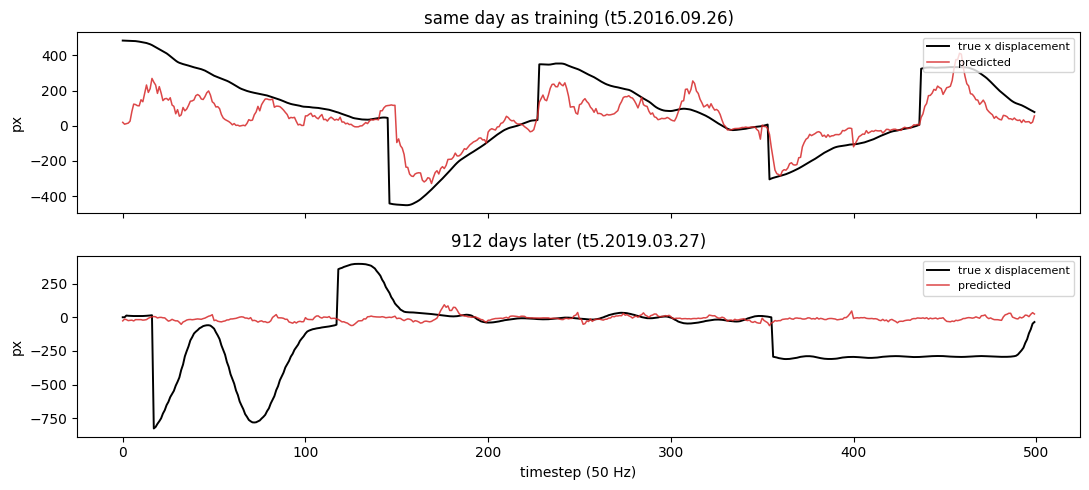

In [12]:
far = SESSIONS[-1]
idx = torch.tensor(np.flatnonzero(session_of == far))
x_far, y_far = prepare(idx)
with torch.no_grad():
    pred_far = (model(x_far) * y_scale).permute(1, 0, 2).reshape(2, -1).numpy()
true_far = (y_far * y_scale).permute(1, 0, 2).reshape(2, -1).numpy()

x_val_p, y_val_p = prepare(val_idx)
with torch.no_grad():
    pred_val = (model(x_val_p) * y_scale).permute(1, 0, 2).reshape(2, -1).numpy()
true_val = (y_val_p * y_scale).permute(1, 0, 2).reshape(2, -1).numpy()

window = slice(0, 500)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for ax, (pred, true, title) in zip(
    axes,
    [
        (pred_val, true_val, f"same day as training ({TRAIN_SESSION})"),
        (pred_far, true_far, f"{gaps[-1]} days later ({far})"),
    ],
):
    ax.plot(true[0][window], color="k", lw=1.4, label="true x displacement")
    ax.plot(pred[0][window], color="tab:red", lw=1.1, alpha=0.85, label="predicted")
    ax.set_ylabel("px")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)
axes[1].set_xlabel("timestep (50 Hz)")
fig.tight_layout()

## Honest reading, and what was left on the table

The within-day fit is modest and the model clearly overfits: training-block `r` reaches 0.99 against 0.76 on held-out blocks of the same day, and the training loss keeps falling while validation loss flattens after roughly ten epochs. With only 673 windows, about 11 minutes of data, that is expected. The point of the notebook is the shape of the decay, and overfitting the training day does not distort that, since every test session is evaluated with the same frozen weights.

Levers deliberately not pulled, each of which would lift the numbers:

- **No smoothing.** The reference analyses apply a causal Gaussian filter (sigma of about 40 ms) to the rates before regressing. That alone lifts within-day performance noticeably.
- **One training day, one task.** Adding sessions, adding the `keyboard` and `fitts` blocks (roughly eight more hours), and shortening the stride are all cheap once the extractor cache is warm.
- **No recalibration of any kind.** Normalization statistics are frozen at the training day on purpose. Refitting even the per-channel means on each test day is the paper's cheapest baseline and would visibly lift the intermediate gaps.
- **No regularization tuning.** A smaller model or stronger dropout would close some of the train/validation gap.

The more important caveat is what the ceiling is made of. When validation metrics stop moving as capacity or regularization are tuned, the limit is the representation rather than the model. Within a day that is arguably still a model-and-data-quantity problem here. Across sessions it is unambiguously not: no capacity change fixes a decoder whose input distribution has moved underneath it, which is exactly the problem this dataset exists to pose.